# EDA combined: solar generation and radiation

**Step 3 of the EDA guide:** the relationship between our target and the explanatory data. Both sources were studied separately first:
`../energy_charts/energy_charts_eda.ipynb` (target) and `../meteoswiss/meteoswiss_eda.ipynb` (weather). The decisions from their decision logs are applied here.

| | |
|---|---|
| Solar | Energy-Charts (Fraunhofer ISE), Swiss solar generation, CC BY 4.0, attribution "energy-charts.info" |
| Radiation | MeteoSwiss, global radiation, mean of Luzern, Mosen, Schüpfheim, Egolzwil; Pilatus separately. CC BY 4.0, "Source: MeteoSwiss" |
| Period | 2019–2025, hourly, fixed CET (UTC+1), every stamp marks the start of the hour |
| Still missing | SFOE register (installed capacity) and Open-Meteo forecasts: Flurin's notebooks, added later |

**How this notebook works:** every section starts with a **question**, then the code, a chart, and a note **Finding → Consequence**.
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
FIG = Path("../../figures/eda")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"combined_{name}.png", dpi=160, bbox_inches="tight")

## Load and clean, applying the decision logs of both notebooks

In [2]:
def load_solar():
    frames = []
    for f in sorted(Path("../energy_charts/data").glob("public_power_ch_*.json")):
        d = json.loads(f.read_text(encoding="utf-8"))
        data = next(p["data"] for p in d["production_types"] if p["name"] == "Solar")
        frames.append(pd.Series(data, index=pd.to_datetime(d["unix_seconds"], unit="s", utc=True), dtype="float64"))
    s = pd.concat(frames)
    return s[~s.index.duplicated()].sort_index().tz_convert(TZ)


def load_radiation(abbr):
    files = sorted(Path("../meteoswiss/data").glob(f"ogd-smn_{abbr}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", "gre000h0"]) for f in files)
    d["time"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ) - pd.Timedelta(hours=1)
    return d.drop_duplicates("time", keep="last").set_index("time")["gre000h0"]


solar_raw = load_solar()
daily_raw = solar_raw.resample("D").sum() / 1000
typical = daily_raw.rolling(15, center=True, min_periods=7).median()
flagged = daily_raw[daily_raw < 0.10 * typical].loc["2019":"2025"].index
flagged = flagged.drop(pd.Timestamp("2024-11-22", tz=TZ))      # real: 36 cm of snow (Energy-Charts notebook, Q5b)

solar = solar_raw.loc["2019":"2025"].copy()
solar[solar.index.normalize().isin(flagged)] = np.nan          # suspicious days become missing
night = solar.index.hour.isin([22, 23, 0, 1, 2, 3])
solar[night & (solar > 100)] = np.nan                          # the two 415 MW values in September 2022

stations = {a: load_radiation(a.lower()).reindex(solar.index) for a in ["LUZ", "MOA", "SPF", "EGO", "PIL"]}
radiation = pd.DataFrame(stations)
radiation[night] = 0                                           # sensor offsets at night (MeteoSwiss notebook, Q7)
sun = radiation[["LUZ", "MOA", "SPF", "EGO"]].mean(axis=1)     # the "radiation average"

data = pd.DataFrame({"solar_MW": solar, "sun_W_m2": sun, "sun_LUZ": radiation["LUZ"], "pilatus": radiation["PIL"]})
print("Hours:", len(data), "| days set to missing:", len(flagged), "| empty solar hours:", data["solar_MW"].isna().sum(), "| empty radiation hours:", data["sun_W_m2"].isna().sum())

# Daily values. Solar is divided by its annual mean, a simple way to remove the growth of the fleet for now.
# Flurin's register will replace this with the proper capacity factor (generation / installed capacity).
daily = pd.DataFrame({
    "solar_GWh": data["solar_MW"].resample("D").sum(min_count=20) / 1000,
    "sun": data["sun_W_m2"].resample("D").sum(min_count=20) / 1000,
    "sun_LUZ": data["sun_LUZ"].resample("D").sum(min_count=20) / 1000,
    "pilatus": data["pilatus"].resample("D").sum(min_count=20) / 1000,
})
daily["solar_rel"] = daily["solar_GWh"] / daily["solar_GWh"].groupby(daily.index.year).transform("mean")
daily.head()

Hours: 61368 | days set to missing: 11 | empty solar hours: 266 | empty radiation hours: 0


,solar_GWh,sun,sun_LUZ,pilatus,solar_rel
2019-01-01 00:00:00+01:00,1.0144,0.78250,0.643,1.969,0.164905
2019-01-02 00:00:00+01:00,1.4284,0.79275,0.832,0.566,0.232206
2019-01-03 00:00:00+01:00,2.3936,1.64850,1.658,1.911,0.389113
2019-01-04 00:00:00+01:00,2.8799,1.67925,1.725,1.911,0.468168
2019-01-05 00:00:00+01:00,0.3428,0.38500,0.309,0.498,0.055727


## Q1: Radiation average and reported solar GW on top of each other. Do they move together?

Same weeks in two years side by side. Both curves are divided by their highest value in the panel, so they share one scale; the real highest values are written in each panel.

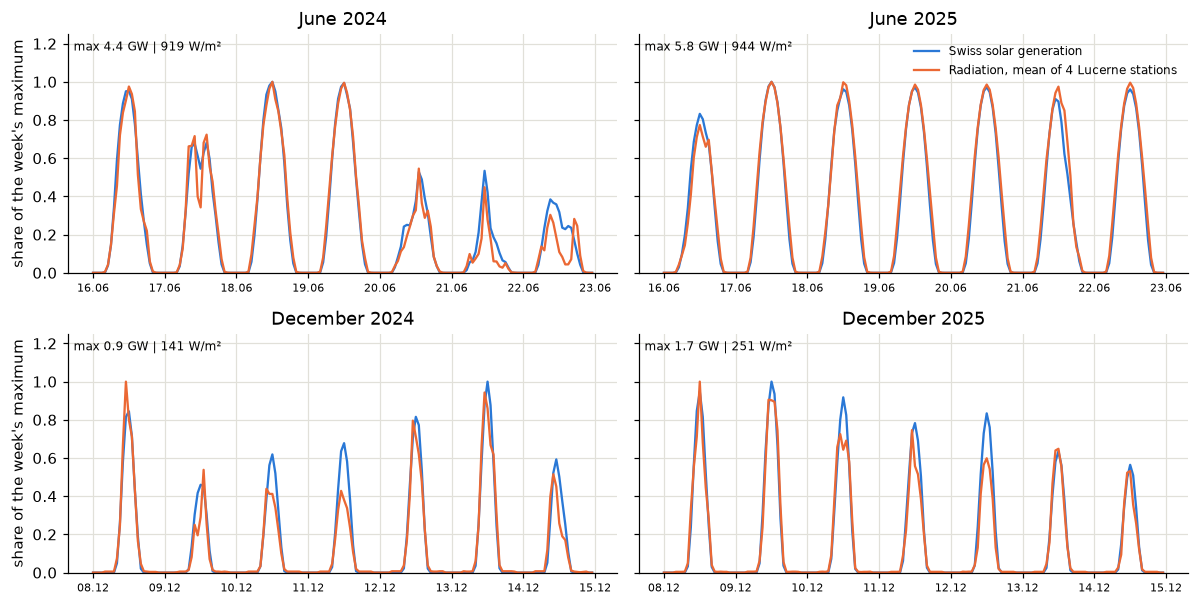

In [3]:
weeks = [("06-16", "06-22", "June"), ("12-08", "12-14", "December")]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey=True)
for row, (a, b, label) in enumerate(weeks):
    for col, year in enumerate([2024, 2025]):
        ax = axes[row, col]
        w = data.loc[f"{year}-{a}":f"{year}-{b}"]
        ax.plot(w.index, w["solar_MW"] / w["solar_MW"].max(), color=BLUE, label="Swiss solar generation")
        ax.plot(w.index, w["sun_W_m2"] / w["sun_W_m2"].max(), color=ORANGE, label="Radiation, mean of 4 Lucerne stations")
        ax.set_title(f"{label} {year}")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m", tz=TZ))
        ax.tick_params(axis="x", labelsize=7)
        ax.text(0.01, 0.97, f"max {w['solar_MW'].max() / 1000:.1f} GW | {w['sun_W_m2'].max():.0f} W/m²", transform=ax.transAxes, va="top", fontsize=8)
        ax.set_ylim(0, 1.25)
    axes[row, 0].set_ylabel("share of the week's maximum")
axes[0, 1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
save(fig, "overlay_weeks")
plt.show()

> **Finding:** the two curves follow each other almost hour by hour, in summer and in winter, including cloudy days (e.g. 20–22 June 2024). The match is less tight in December. The highest solar value also grows much faster than the radiation (June: 4.4 → 5.8 GW with 919 → 944 W/m²).
> **Consequence:** the Lucerne radiation average is a good explanatory variable for Swiss solar generation. The growth of the fleet must be separated from the weather, which is what the installed capacity from the SFOE register (Flurin) is for.

## Q2: And over a whole year?

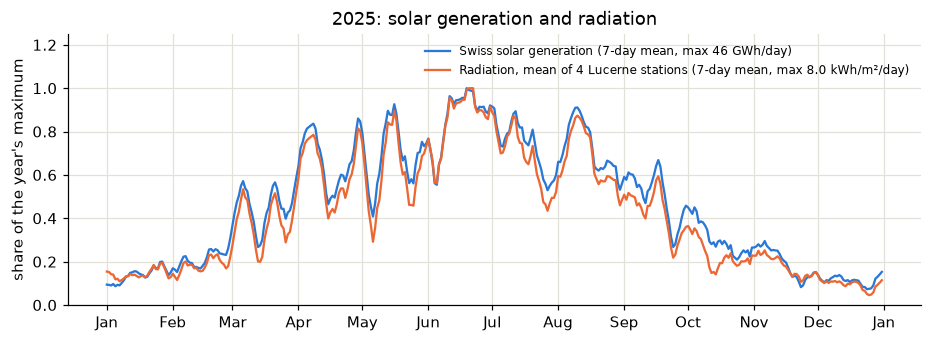

Daily Pearson r in 2025: 0.985


In [4]:
year = daily.loc["2025"]
smooth = year[["solar_GWh", "sun"]].rolling(7, center=True, min_periods=4).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(smooth.index, smooth["solar_GWh"] / smooth["solar_GWh"].max(), color=BLUE, label=f"Swiss solar generation (7-day mean, max {smooth['solar_GWh'].max():.0f} GWh/day)")
ax.plot(smooth.index, smooth["sun"] / smooth["sun"].max(), color=ORANGE, label=f"Radiation, mean of 4 Lucerne stations (7-day mean, max {smooth['sun'].max():.1f} kWh/m²/day)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b", tz=TZ))
ax.xaxis.set_major_locator(mdates.MonthLocator(tz=TZ))
ax.set_ylim(0, 1.25)
ax.set_ylabel("share of the year's maximum")
ax.set_title("2025: solar generation and radiation")
ax.legend(frameon=False, fontsize=8, loc="upper right")
save(fig, "overlay_2025")
plt.show()
print("Daily Pearson r in 2025:", round(year["solar_GWh"].corr(year["sun"]), 3))

> **Finding:** over the year both curves have the same shape (daily Pearson r = 0.985 in 2025). In spring and autumn solar stays a little above the radiation.
> **Consequence:** one linear scale between radiation and solar does not fit all seasons equally. **To question:** is this because tilted panels catch the low sun better? The register has the tilt; the fleet's growth during the year may also play a part.

## Q3: Do the time stamps of both sources line up?

In [5]:
pair = data[["solar_MW", "sun_W_m2"]].dropna()
lags = {k: round(pair["solar_MW"].corr(pair["sun_W_m2"].shift(k)), 3) for k in range(-3, 4)}
pd.Series(lags, name="Pearson r, hourly").rename_axis("radiation shifted by hours").to_frame().T

radiation shifted by hours,-3,-2,-1,0,1,2,3
"Pearson r, hourly",0.564,0.717,0.822,0.86,0.82,0.712,0.559


> **Finding:** the correlation is highest with **no shift** and falls off evenly on both sides, so the time stamps are aligned after our conversion (fixed CET, MeteoSwiss −1 h). The level of r here (0.86) is lower than in Q4 because these are raw MW, which include the fleet's growth.
> **Consequence:** the alignment is confirmed, and the combined dataset can use these time stamps.

## Q4: How strong is the relationship? By season, and with one station or four?

Hourly Pearson r, all year, mean of 4 stations: 0.977 | Luzern only: 0.955
Daily Pearson r per year: {2019: 0.973, 2020: 0.985, 2021: 0.969, 2022: 0.982, 2023: 0.978, 2024: 0.976, 2025: 0.985}


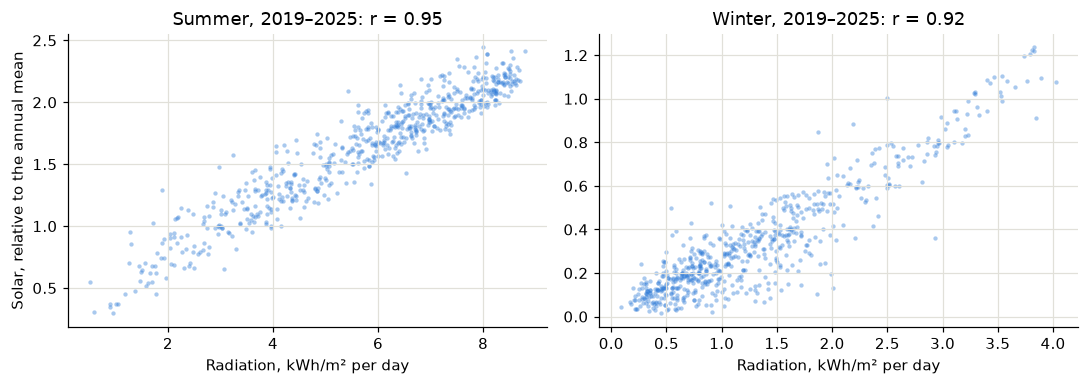

,"daily r, mean of 4 stations","daily r, Luzern only"
season,,
winter,0.916,0.889
spring,0.958,0.926
summer,0.950,0.922
autumn,0.968,0.940
all year,0.973,0.956


In [6]:
season_of = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
             6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
d = daily.dropna(subset=["solar_rel", "sun", "sun_LUZ"]).copy()
d["season"] = d.index.month.map(season_of)
strength = pd.DataFrame({
    "daily r, mean of 4 stations": d.groupby("season").apply(lambda t: t["solar_rel"].corr(t["sun"]), include_groups=False),
    "daily r, Luzern only": d.groupby("season").apply(lambda t: t["solar_rel"].corr(t["sun_LUZ"]), include_groups=False),
}).reindex(["winter", "spring", "summer", "autumn"])
strength.loc["all year"] = [d["solar_rel"].corr(d["sun"]), d["solar_rel"].corr(d["sun_LUZ"])]
strength = strength.round(3)

h = data.dropna(subset=["solar_MW", "sun_W_m2"]).copy()
h["solar_rel"] = h["solar_MW"] / h["solar_MW"].groupby(h.index.year).transform("mean")
print("Hourly Pearson r, all year, mean of 4 stations:", round(h["solar_rel"].corr(h["sun_W_m2"]), 3), "| Luzern only:", round(h["solar_rel"].corr(h["sun_LUZ"]), 3))
print("Daily Pearson r per year:", d.groupby(d.index.year).apply(lambda t: round(t["solar_GWh"].corr(t["sun"]), 3), include_groups=False).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, s in zip(axes, ["summer", "winter"]):
    t = d[d["season"] == s]
    ax.scatter(t["sun"], t["solar_rel"], s=8, color=BLUE, alpha=0.4, linewidths=0)
    ax.set_title(f"{s.capitalize()}, 2019–2025: r = {strength.loc[s, 'daily r, mean of 4 stations']:.2f}")
    ax.set_xlabel("Radiation, kWh/m² per day")
axes[0].set_ylabel("Solar, relative to the annual mean")
plt.tight_layout()
save(fig, "scatter_summer_winter")
plt.show()
strength

> **Finding:** this is the first answer to G2. Solar follows the radiation strongly: daily Pearson r = 0.973 over the year and 0.92–0.97 within each season, so the relationship is not just the shared seasons. Winter is the weakest (0.916), which the scatter shows as a wider cloud. The **mean of four stations beats Luzern alone in every season**, by 0.02–0.03.
> **Consequence:** use the four-station mean. *These r values compare Swiss solar with Lucerne weather, using solar relative to its annual mean; they are to be repeated with the capacity factor from the register.*

## Q5: Why is winter weaker? Does fog explain it?

Share of fog days: 15 %
Solar compared with the Lucerne-based fit (median): {'other days': 0.99, 'fog days': 1.27}
R² October to February, Lucerne radiation only: 0.851 | with Pilatus as well: 0.867


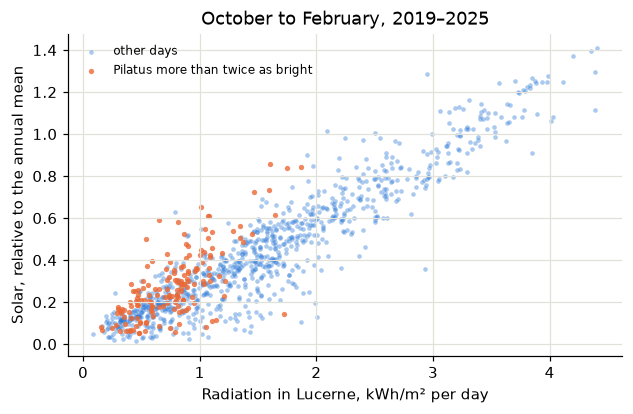

In [7]:
w = d[d.index.month.isin([10, 11, 12, 1, 2])].dropna(subset=["pilatus"]).copy()
w["fog"] = (w["pilatus"] > 2 * w["sun"]) & (w["pilatus"] >= 1.5)   # same definition as in the MeteoSwiss notebook, Q11

fit = sm.OLS(w["solar_rel"], sm.add_constant(w[["sun"]])).fit()
fit2 = sm.OLS(w["solar_rel"], sm.add_constant(w[["sun", "pilatus"]])).fit()
w["expected"] = fit.predict()
above = (w["solar_rel"] / w["expected"]).groupby(w["fog"]).median()
print(f"Share of fog days: {w['fog'].mean() * 100:.0f} %")
print("Solar compared with the Lucerne-based fit (median):", {("fog days" if k else "other days"): round(v, 2) for k, v in above.items()})
print("R² October to February, Lucerne radiation only:", round(fit.rsquared, 3), "| with Pilatus as well:", round(fit2.rsquared, 3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(w.loc[~w["fog"], "sun"], w.loc[~w["fog"], "solar_rel"], s=9, color=BLUE, alpha=0.4, linewidths=0, label="other days")
ax.scatter(w.loc[w["fog"], "sun"], w.loc[w["fog"], "solar_rel"], s=12, color=ORANGE, alpha=0.8, linewidths=0, label="Pilatus more than twice as bright")
ax.set_xlabel("Radiation in Lucerne, kWh/m² per day")
ax.set_ylabel("Solar, relative to the annual mean")
ax.set_title("October to February, 2019–2025")
ax.legend(frameon=False, fontsize=8)
save(fig, "winter_fog")
plt.show()

> **Finding:** on the 15 % of winter days with much more radiation on Pilatus, Swiss solar is about **27 % higher** than the Lucerne radiation suggests (median; other days: 1 % lower). Many panels are probably above the fog or low cloud, or simply elsewhere in Switzerland. Adding Pilatus raises R² only slightly, from 0.85 to 0.87 (same data, not a forecast test).
> **Consequence:** fog explains part of the weak winter, but not all of it; the spread remains on other days too. Whether Pilatus is worth including is decided when modelling, on a held-out period. Snow on panels is another possible cause (see 22.11.2024).

# Summary

| # | Finding | Consequence |
|---|---|---|
| Q1, Q2 | Radiation and solar move together almost hour by hour | radiation is the right explanatory variable |
| Q2 | Solar slightly above radiation in spring and autumn | to question: tilt of the panels? |
| Q3 | Time stamps aligned, highest correlation at no shift | conversion confirmed |
| Q4 | Daily r = 0.973; 0.92–0.97 per season; winter weakest | four-station mean instead of Luzern alone |
| Q5 | About 27 % more solar than expected on fog days | Pilatus as a candidate input, to be tested on held-out data |

## Is the data suitable? (Insights)

**Yes for G2:** the weather explains most of the day-to-day changes in solar generation. **Two limits remain:** this compares *national* solar with *Lucerne* weather, so it says nothing yet about Lucerne's own output; and it uses *measured* weather, which is not available for a real forecast.

## Open questions (to discuss)

1. Is the Lucerne radiation average good enough for national solar, or do we need stations from other regions as well?
2. Is fixed CET what was meant by "European time"?

## Next steps

- Add from Flurin: **installed capacity** (capacity factor instead of the annual mean) and **Open-Meteo forecasts** (how good is a forecast compared with measured radiation?).
- Then: the 3 slides, and the README sections for Deliverable 3.